## Filter-based feature selection (no model training)

Each cell ranks columns by mutual information with cancellation using the training period only. Mutual information is a filter score: no classifier is fitted. Each block keeps the top half of its candidate columns as an exploratory subset. The all-source block excludes `is_canceled` from inputs; it includes outcome-related and post-booking columns only as a leakage diagnostic, never as a deployable feature list. Validate a final set on choose data, and treat the already-inspected proof period as a secondary evaluation.


In [4]:
from pathlib import Path
import sys
import math

import pandas as pd
from IPython.display import display
from sklearn.feature_selection import mutual_info_classif

# Support running this notebook with the project root or notebooks/ as the working directory.
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import contract
import data
import features

raw_df = data.read_raw()
prepared_df = features.prepare_bookings(raw_df)
train_df, choose_df, proof_df = contract.split_periods(prepared_df)
y_train = train_df[features.TARGET]

def rank_features_by_mutual_information(candidate_columns, set_name):
    """Rank original columns using training-period mutual information only."""
    rows = []
    for column in candidate_columns:
        values = train_df[column]
        if pd.api.types.is_numeric_dtype(values):
            numeric_values = values.fillna(values.median()).to_numpy(dtype=float).reshape(-1, 1)
            score = mutual_info_classif(
                numeric_values, y_train, discrete_features=False, random_state=42
            )[0]
        else:
            category_codes = pd.factorize(
                values.fillna("unknown").astype(str), sort=True
            )[0].reshape(-1, 1)
            score = mutual_info_classif(
                category_codes, y_train, discrete_features=True, random_state=42
            )[0]
        rows.append({"Feature": column, "Mutual information": float(score)})

    ranking = pd.DataFrame(rows).sort_values(
        "Mutual information", ascending=False
    ).reset_index(drop=True)
    keep_count = max(1, math.ceil(len(candidate_columns) / 2))
    ranking.insert(0, "Feature set", set_name)
    ranking["Selected"] = ranking.index < keep_count
    return ranking

# Block 1: all source columns (32 total, minus is_canceled as the target = 31 predictors).
all_source_predictors = [
    column for column in raw_df.columns
    if column != features.TARGET
]
all_columns_selection_df = rank_features_by_mutual_information(
    all_source_predictors, "All 31 source predictors"
)
all_columns_selected = all_columns_selection_df.loc[
    all_columns_selection_df["Selected"], "Feature"
].tolist()
print("Source columns:", len(raw_df.columns), "including the target")
print("Predictors ranked:", len(all_source_predictors))
print("Selected features:", all_columns_selected)
display(all_columns_selection_df)


Source columns: 32 including the target
Predictors ranked: 31
Selected features: ['reservation_status', 'reservation_status_date', 'deposit_type', 'lead_time', 'previous_cancellations', 'adr', 'country', 'agent', 'market_segment', 'assigned_room_type', 'total_of_special_requests', 'days_in_waiting_list', 'required_car_parking_spaces', 'booking_changes', 'distribution_channel', 'hotel']


,Feature set,Feature,Mutual information,Selected
0,All 31 source predictors,reservation_status,0.653596,True
1,All 31 source predictors,reservation_status_date,0.202442,True
2,All 31 source predictors,deposit_type,0.173386,True
3,All 31 source predictors,lead_time,0.128023,True
4,All 31 source predictors,previous_cancellations,0.118255,True
5,All 31 source predictors,adr,0.113767,True
6,All 31 source predictors,country,0.113420,True
7,All 31 source predictors,agent,0.102697,True
8,All 31 source predictors,market_segment,0.050290,True
9,All 31 source predictors,assigned_room_type,0.046958,True


In [5]:
# Block 2: the team's approved 17 model features.
seventeen_feature_selection_df = rank_features_by_mutual_information(
    features.MODEL_FEATURES, "Approved 17 features"
)
seventeen_features_selected = seventeen_feature_selection_df.loc[
    seventeen_feature_selection_df["Selected"], "Feature"
].tolist()
print("Approved features ranked:", len(features.MODEL_FEATURES))
print("Selected features:", seventeen_features_selected)
display(seventeen_feature_selection_df)


Approved features ranked: 17
Selected features: ['lead_time', 'previous_cancellations', 'country', 'agent', 'market_segment', 'distribution_channel', 'hotel', 'arrival_date_week_number', 'company']


,Feature set,Feature,Mutual information,Selected
0,Approved 17 features,lead_time,0.128023,True
1,Approved 17 features,previous_cancellations,0.118255,True
2,Approved 17 features,country,0.113420,True
3,Approved 17 features,agent,0.102697,True
4,Approved 17 features,market_segment,0.050290,True
5,Approved 17 features,distribution_channel,0.015464,True
6,Approved 17 features,hotel,0.013781,True
7,Approved 17 features,arrival_date_week_number,0.013436,True
8,Approved 17 features,company,0.012563,True
9,Approved 17 features,reserved_room_type,0.008193,False


In [6]:
# Block 3: the nine fields classified as Bin 1 in docs/COLUMNS.md.
bin1_features = [
    "hotel",
    "market_segment",
    "distribution_channel",
    "is_repeated_guest",
    "previous_cancellations",
    "previous_bookings_not_canceled",
    "agent",
    "company",
    "customer_type",
]
nine_feature_selection_df = rank_features_by_mutual_information(
    bin1_features, "Nine Bin 1 candidates"
)
nine_features_selected = nine_feature_selection_df.loc[
    nine_feature_selection_df["Selected"], "Feature"
].tolist()
print("Bin 1 candidates ranked:", len(bin1_features))
print("Selected features:", nine_features_selected)
display(nine_feature_selection_df)


Bin 1 candidates ranked: 9
Selected features: ['previous_cancellations', 'agent', 'market_segment', 'distribution_channel', 'hotel']


,Feature set,Feature,Mutual information,Selected
0,Nine Bin 1 candidates,previous_cancellations,0.118255,True
1,Nine Bin 1 candidates,agent,0.102697,True
2,Nine Bin 1 candidates,market_segment,0.050290,True
3,Nine Bin 1 candidates,distribution_channel,0.015464,True
4,Nine Bin 1 candidates,hotel,0.013781,True
5,Nine Bin 1 candidates,company,0.012563,False
6,Nine Bin 1 candidates,previous_bookings_not_canceled,0.004410,False
7,Nine Bin 1 candidates,customer_type,0.003717,False
8,Nine Bin 1 candidates,is_repeated_guest,0.000000,False


## Exploratory visualizations

These charts use `prepared_df`, the approved scoring population after the documented 827-row exclusions. Exact duplicates remain. The charts are descriptive; they do not select model settings or modify the scoring population. `is_canceled` is shown only as an outcome, never as a model input.


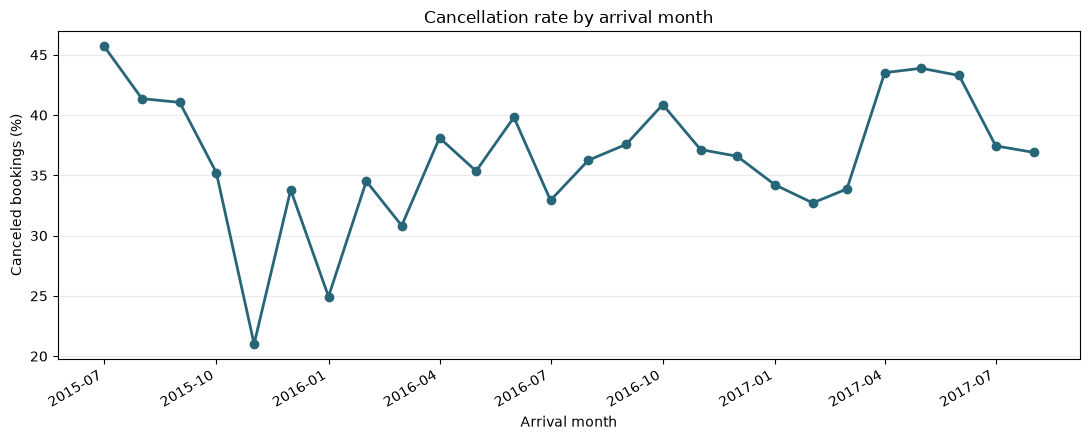

In [7]:
import matplotlib.pyplot as plt
import numpy as np

# Monthly cancellation rate across the approved filtered population.
monthly = prepared_df.assign(month=prepared_df["arrival_date"].dt.to_period("M").dt.to_timestamp()).groupby("month")[features.TARGET].mean()
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(monthly.index, monthly.values * 100, marker="o", linewidth=2, color="#276678")
ax.set(title="Cancellation rate by arrival month", xlabel="Arrival month", ylabel="Canceled bookings (%)")
ax.grid(axis="y", alpha=0.25)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()


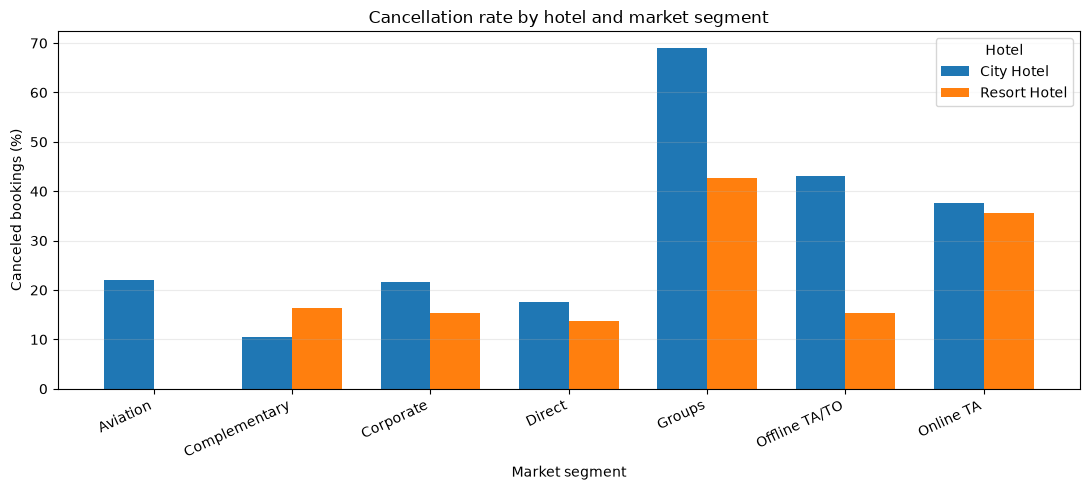

In [8]:
# Cancellation rates by hotel and market segment (small categories omitted for readability).
segment_rates = prepared_df.groupby(["hotel", "market_segment"])[features.TARGET].agg(["mean", "size"]).reset_index()
segment_rates = segment_rates[segment_rates["size"] >= 100].copy()
fig, ax = plt.subplots(figsize=(11, 5))
segments = segment_rates["market_segment"].drop_duplicates().tolist()
x = np.arange(len(segments))
width = 0.36
for offset, hotel in zip([-width / 2, width / 2], sorted(segment_rates["hotel"].unique())):
    values = segment_rates[segment_rates["hotel"] == hotel].set_index("market_segment")["mean"]
    ax.bar(x + offset, [values.get(segment, np.nan) * 100 for segment in segments], width, label=hotel)
ax.set_xticks(x, segments, rotation=25, ha="right")
ax.set(title="Cancellation rate by hotel and market segment", xlabel="Market segment", ylabel="Canceled bookings (%)")
ax.legend(title="Hotel")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


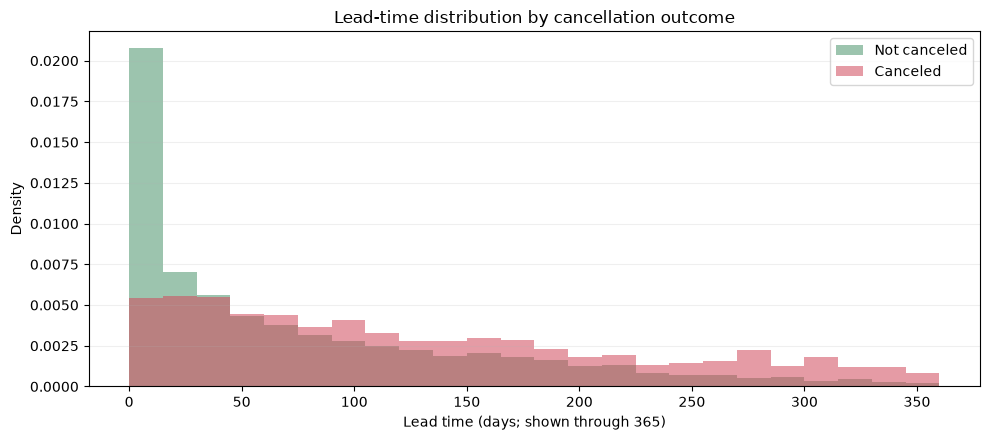

In [9]:
# Booking lead-time distributions by observed outcome, with a log-count axis for the long tail.
fig, ax = plt.subplots(figsize=(10, 4.5))
for canceled, label, color in [(0, "Not canceled", "#4c956c"), (1, "Canceled", "#d1495b")]:
    values = prepared_df.loc[prepared_df[features.TARGET] == canceled, "lead_time"]
    ax.hist(values, bins=np.arange(0, 366, 15), density=True, alpha=0.55, label=label, color=color)
ax.set(title="Lead-time distribution by cancellation outcome", xlabel="Lead time (days; shown through 365)", ylabel="Density")
ax.legend()
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()


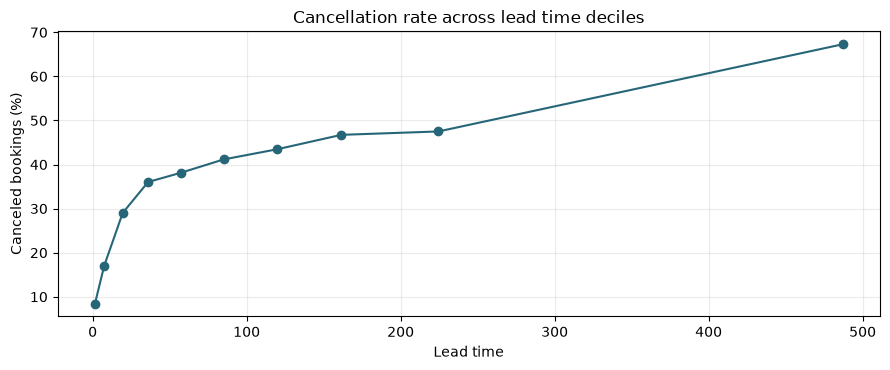

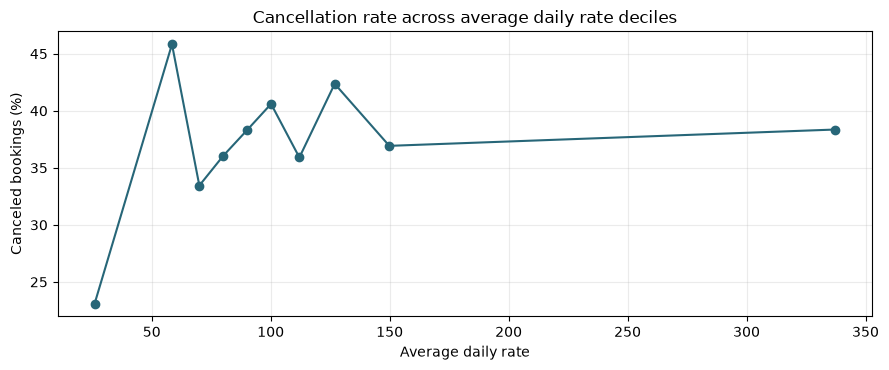

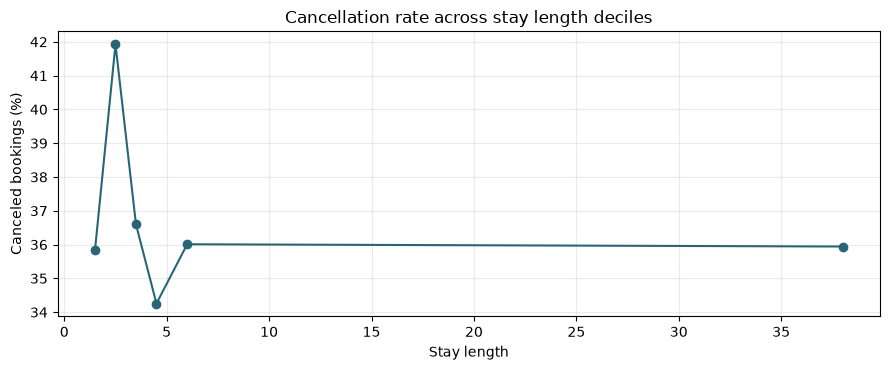

In [10]:
# Cancellation rates across selected numeric booking characteristics.
# Quantile bins make rates comparable despite highly skewed raw counts.
for column, title in [("lead_time", "Lead time"), ("adr", "Average daily rate"), ("nights", "Stay length")]:
    binned = pd.qcut(prepared_df[column], q=10, duplicates="drop")
    summary = prepared_df.groupby(binned, observed=True)[features.TARGET].agg(["mean", "size"]).reset_index()
    centers = [interval.mid for interval in summary[column]]
    fig, ax = plt.subplots(figsize=(9, 3.8))
    ax.plot(centers, summary["mean"] * 100, marker="o", color="#276678")
    ax.set(title=f"Cancellation rate across {title.lower()} deciles", xlabel=title, ylabel="Canceled bookings (%)")
    ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()


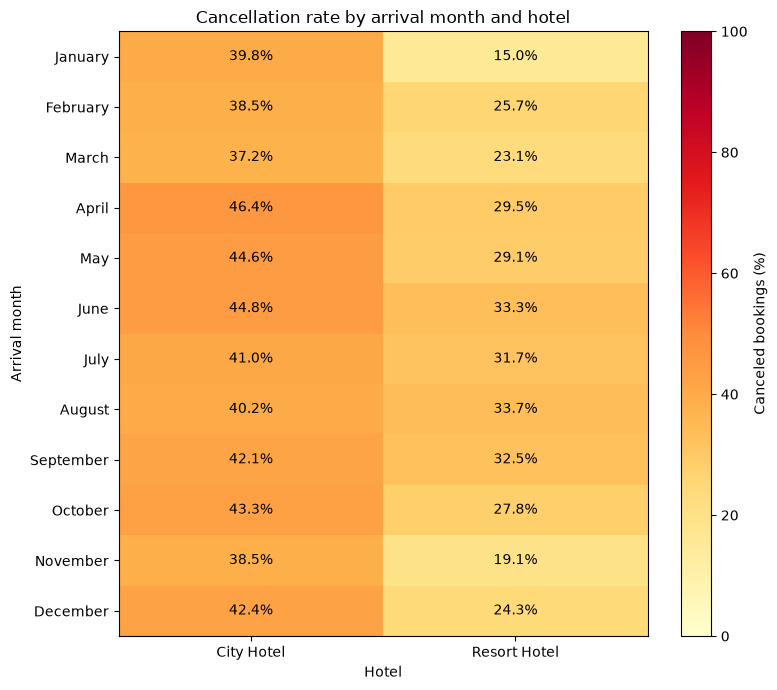

In [12]:
monthly_hotel_rate = prepared_df.assign(
    arrival_month=prepared_df["arrival_date"].dt.month_name()
).pivot_table(
    index="arrival_month",
    columns="hotel",
    values=features.TARGET,
    aggfunc="mean",
)

month_order = [
    "January", "February", "March", "April", "May", "June",
    "July", "August", "September", "October", "November", "December",
]
monthly_hotel_rate = monthly_hotel_rate.reindex(month_order)

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(
    monthly_hotel_rate * 100,
    cmap="YlOrRd",
    aspect="auto",
    vmin=0,
    vmax=100,
)

ax.set_xticks(range(len(monthly_hotel_rate.columns)), monthly_hotel_rate.columns)
ax.set_yticks(range(len(monthly_hotel_rate.index)), monthly_hotel_rate.index)
ax.set(
    title="Cancellation rate by arrival month and hotel",
    xlabel="Hotel",
    ylabel="Arrival month",
)

for row in range(monthly_hotel_rate.shape[0]):
    for col in range(monthly_hotel_rate.shape[1]):
        value = monthly_hotel_rate.iloc[row, col]
        if pd.notna(value):
            ax.text(col, row, f"{value:.1%}", ha="center", va="center")

fig.colorbar(im, ax=ax, label="Canceled bookings (%)")
plt.tight_layout()
plt.show()